# Student Performance & Academic Analytics

**Student Name:** Tripti

**Course:** B.Tech CSE (Artificial Intelligence & Machine Learning)

**Institution:** SRM Institute of Science and Technology

**Internship:** BLEEP Education – Artificial Intelligence, June Batch

**Project Type:** Exploratory Data Analysis (EDA)

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import zipfile
import os

%matplotlib inline

In [45]:
df = pd.read_csv("student-mat.csv", sep=";")

In [46]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 1. Data Understanding

The first step is to understand the structure and characteristics of the student performance dataset.

We will examine:
- Dataset dimensions
- First few records
- Data types
- Descriptive statistics
- Numerical and categorical features

In [47]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 395
Number of columns: 33


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [49]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [50]:
df.describe(include="object")

C:\Users\tript\AppData\Local\Temp\ipykernel_18864\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,yes,yes,yes,yes,no
freq,349,208,307,281,354,141,217,145,273,344,242,214,201,314,375,329,263


## 2. Feature Classification

The dataset contains both numerical and categorical variables.

Identifying these feature types helps us choose appropriate statistical methods and visualizations for the EDA.

In [51]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include="object").columns.tolist()

print("Numerical Features:")
print(numerical_columns)

print("\nCategorical Features:")
print(categorical_columns)

Numerical Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical Features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


C:\Users\tript\AppData\Local\Temp\ipykernel_18864\1104043471.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns.tolist()


In [52]:
print("Number of numerical features:", len(numerical_columns))
print("Number of categorical features:", len(categorical_columns))

Number of numerical features: 16
Number of categorical features: 17


## 3. Data Dictionary

The dataset contains demographic, family, social, academic, and behavioral attributes of students.

Important variables include:

- `school` – Student's school
- `sex` – Student's gender
- `age` – Student's age
- `studytime` – Weekly study time
- `failures` – Number of past class failures
- `absences` – Number of school absences
- `G1` – First-period grade
- `G2` – Second-period grade
- `G3` – Final grade

`G3` is used as the main indicator of final academic performance.

## 4. Data Quality & Cleaning

Before performing exploratory analysis, we check the dataset for missing values, duplicate records, and inconsistent data.

These checks help ensure that the analysis is based on reliable and consistent data.

In [53]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values: 0


In [54]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [55]:
if df.duplicated().sum() > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found. No changes made to the dataset.")

No duplicate rows found. No changes made to the dataset.


In [56]:
print(df.dtypes)

school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object


## 5. Validity & Consistency Checks

We check important numerical and categorical variables for unexpected or invalid values before continuing with exploratory analysis.

In [57]:
print("Age range:", df["age"].min(), "to", df["age"].max())
print("G1 range:", df["G1"].min(), "to", df["G1"].max())
print("G2 range:", df["G2"].min(), "to", df["G2"].max())
print("G3 range:", df["G3"].min(), "to", df["G3"].max())
print("Absences range:", df["absences"].min(), "to", df["absences"].max())

Age range: 15 to 22
G1 range: 3 to 19
G2 range: 0 to 19
G3 range: 0 to 20
Absences range: 0 to 75


In [58]:
print("School:", df["school"].unique())
print("Gender:", df["sex"].unique())
print("Study time:", sorted(df["studytime"].unique()))
print("Failures:", sorted(df["failures"].unique()))

School: <StringArray>
['GP', 'MS']
Length: 2, dtype: str
Gender: <StringArray>
['F', 'M']
Length: 2, dtype: str
Study time: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Failures: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [59]:
outlier_columns = ["age", "absences", "G1", "G2", "G3"]

for column in outlier_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    
    print(f"{column}: {len(outliers)} potential outliers")

age: 1 potential outliers
absences: 15 potential outliers
G1: 0 potential outliers
G2: 13 potential outliers
G3: 0 potential outliers


## 6. Exploratory Data Analysis

Exploratory Data Analysis is used to identify distributions, patterns, relationships, and factors associated with student academic performance.

The analysis is divided into:
- Univariate Analysis
- Bivariate Analysis
- Multivariate Analysis

### 6.1 Univariate Analysis

Univariate analysis examines individual variables to understand their distribution and frequency.

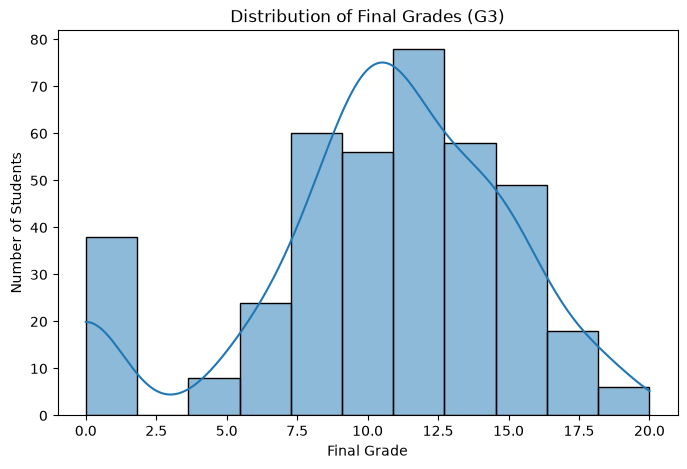

In [60]:
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=11, kde=True)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.show()

**Interpretation:**

The distribution shows how final grades vary across students. It helps identify the most common grade range and whether the distribution is concentrated or spread across the available grade scale.

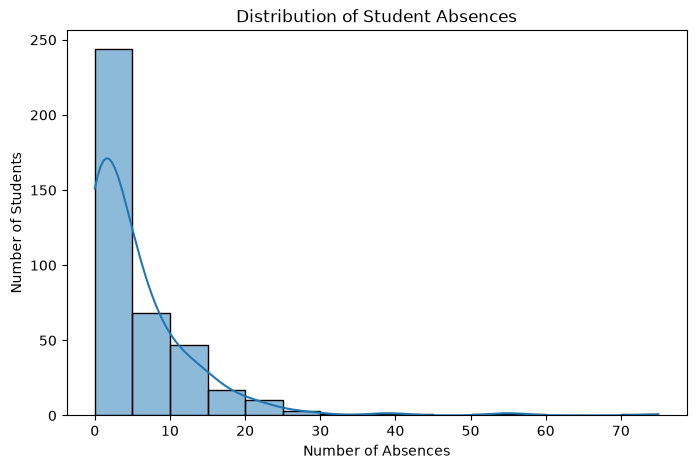

In [61]:
plt.figure(figsize=(8, 5))

sns.histplot(df["absences"], bins=15, kde=True)

plt.title("Distribution of Student Absences")
plt.xlabel("Number of Absences")
plt.ylabel("Number of Students")
plt.show()

**Interpretation:**

The distribution shows how frequently students are absent from school. It helps identify the typical absence range and whether a small number of students have unusually high absences.

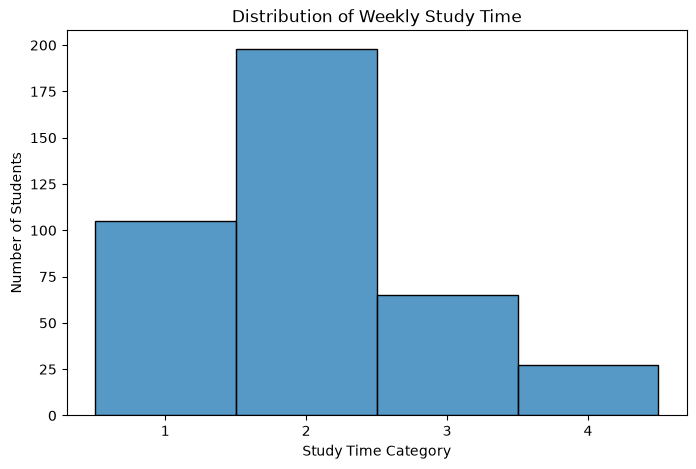

In [62]:
plt.figure(figsize=(8, 5))

sns.histplot(df["studytime"], bins=4, discrete=True)

plt.title("Distribution of Weekly Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Number of Students")
plt.xticks([1, 2, 3, 4])
plt.show()

**Interpretation:**

The distribution shows how students are spread across the different weekly study-time categories. This provides an initial understanding of students' study habits before examining their relationship with academic performance.

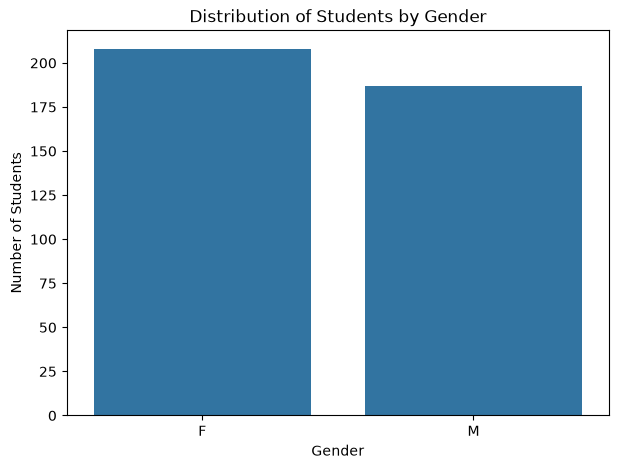

In [63]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex")

plt.title("Distribution of Students by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.show()

**Interpretation:**

The count plot shows the number of students in each gender category. This helps us understand the composition of the dataset before comparing academic performance across gender groups.

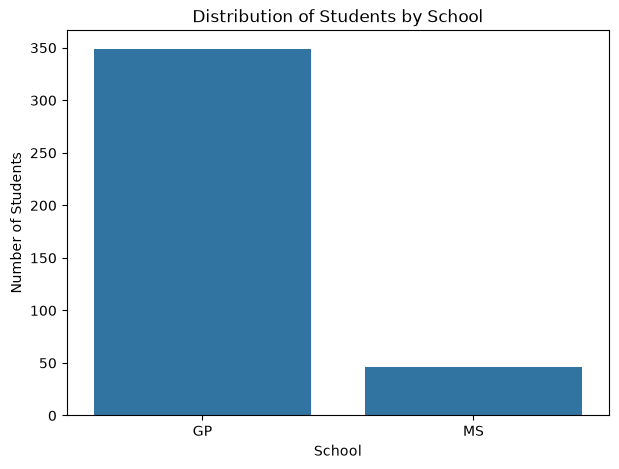

In [64]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="school")

plt.title("Distribution of Students by School")
plt.xlabel("School")
plt.ylabel("Number of Students")
plt.show()

**Interpretation:**

The plot shows the number of students belonging to each school in the dataset. It helps us understand whether the dataset is balanced across the two schools.

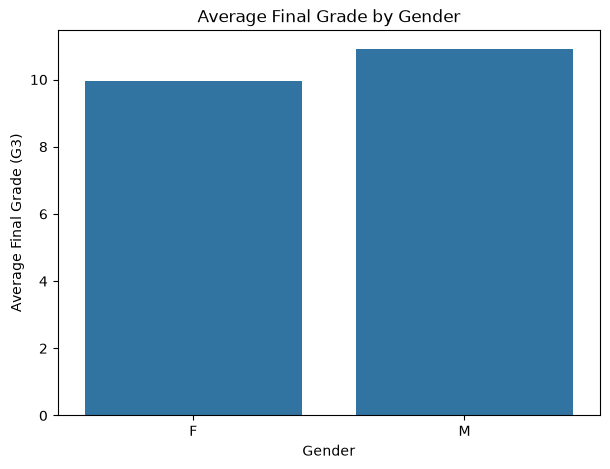

In [65]:
gender_g3 = df.groupby("sex")["G3"].mean().reset_index()

plt.figure(figsize=(7, 5))

sns.barplot(data=gender_g3, x="sex", y="G3")

plt.title("Average Final Grade by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Final Grade (G3)")
plt.show()

**Interpretation:**

The bar chart compares the average final grade between the gender groups. It provides a descriptive view of differences in average academic performance across the groups.

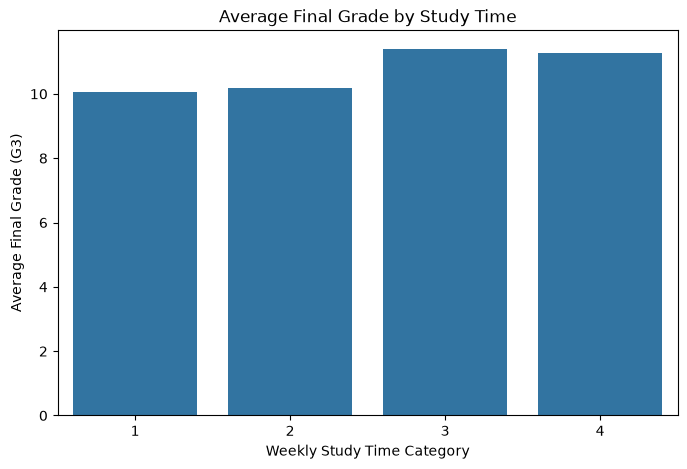

In [66]:
studytime_g3 = df.groupby("studytime")["G3"].mean().reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(data=studytime_g3, x="studytime", y="G3")

plt.title("Average Final Grade by Study Time")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Average Final Grade (G3)")
plt.show()

**Interpretation:**

The chart compares average final grades across weekly study-time categories. It helps examine whether students in different study-time groups show differences in average academic performance.

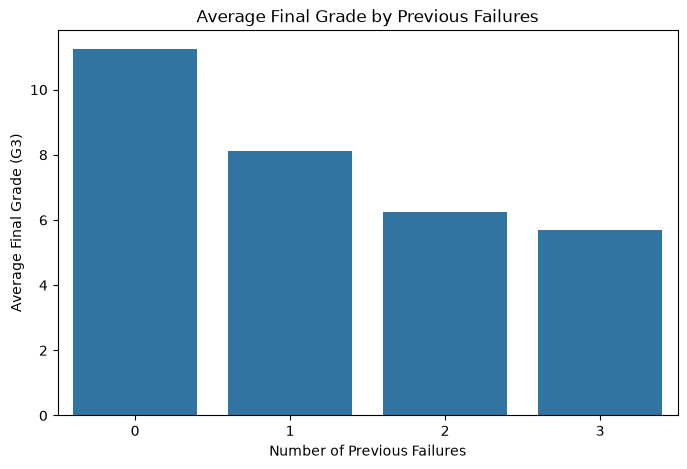

In [67]:
failures_g3 = df.groupby("failures")["G3"].mean().reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(data=failures_g3, x="failures", y="G3")

plt.title("Average Final Grade by Previous Failures")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Average Final Grade (G3)")
plt.show()

**Interpretation:**

The chart compares average final grades according to the number of previous class failures. It helps identify whether students with different academic histories show differences in their final performance.

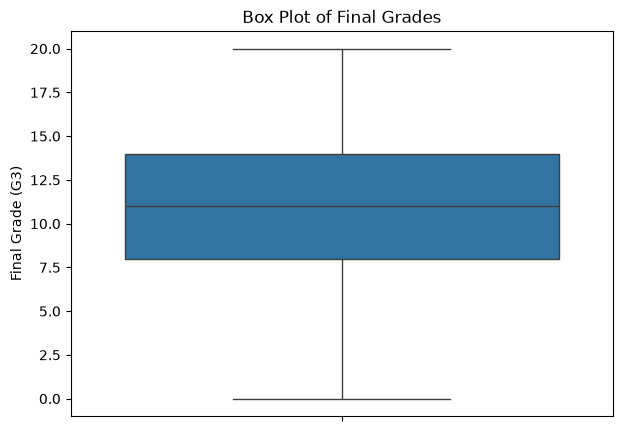

In [68]:
plt.figure(figsize=(7, 5))

sns.boxplot(y=df["G3"])

plt.title("Box Plot of Final Grades")
plt.ylabel("Final Grade (G3)")
plt.show()

**Interpretation:**

The box plot shows the central tendency, spread, and potential outliers in final grades. It helps identify whether some students have unusually high or low final grades.

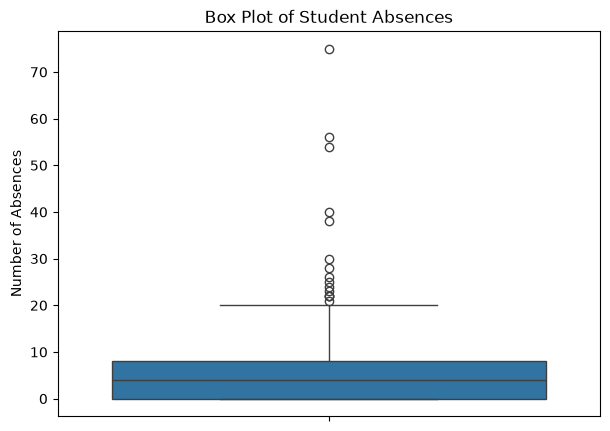

In [69]:
plt.figure(figsize=(7, 5))

sns.boxplot(y=df["absences"])

plt.title("Box Plot of Student Absences")
plt.ylabel("Number of Absences")
plt.show()

**Interpretation:**

The box plot shows the spread of student absences and highlights potential students with unusually high numbers of absences.

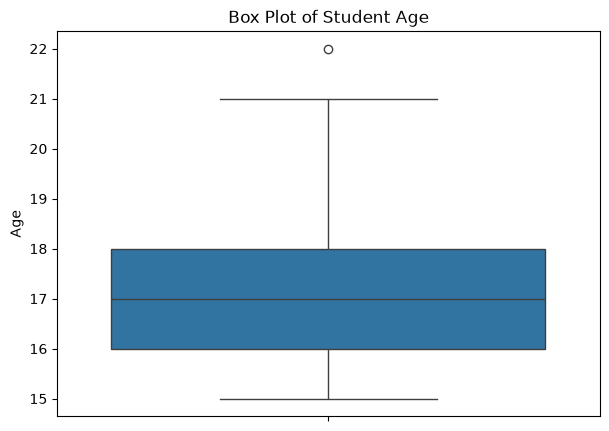

In [70]:
plt.figure(figsize=(7, 5))

sns.boxplot(y=df["age"])

plt.title("Box Plot of Student Age")
plt.ylabel("Age")
plt.show()

**Interpretation:**

The box plot shows the age distribution of students and helps identify the central age range and any potential age-related outliers.

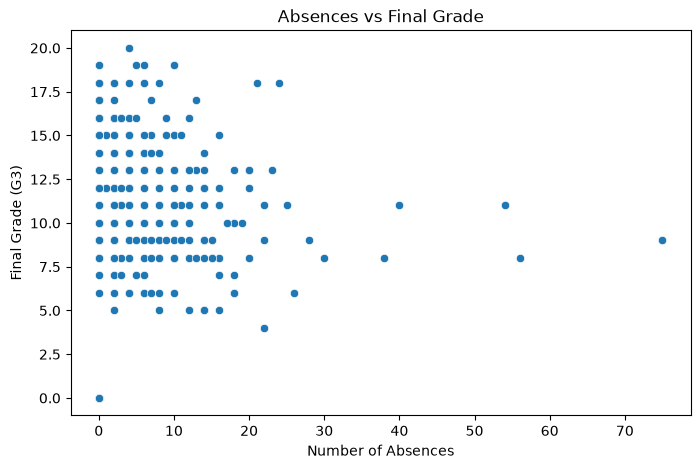

In [71]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="absences", y="G3")

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.show()

**Interpretation:**

The scatter plot shows the relationship between school absences and final grades. It helps us examine whether students with different attendance levels tend to show differences in final academic performance.

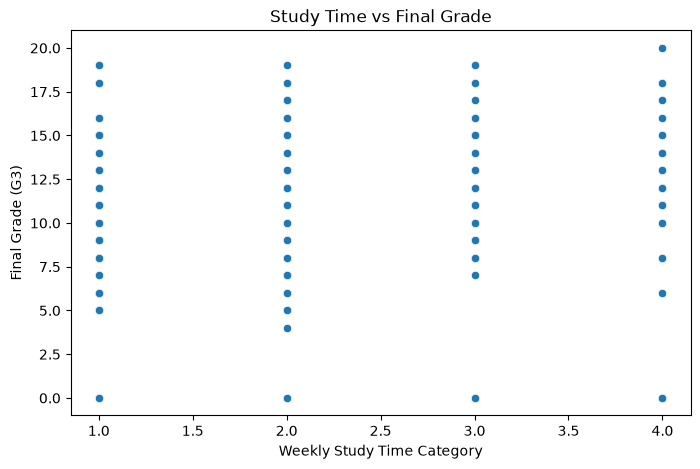

In [72]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Grade")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Final Grade (G3)")
plt.show()

**Interpretation:**

The scatter plot examines the relationship between weekly study time and final grades. It helps identify whether higher study-time categories are associated with different levels of final academic performance.

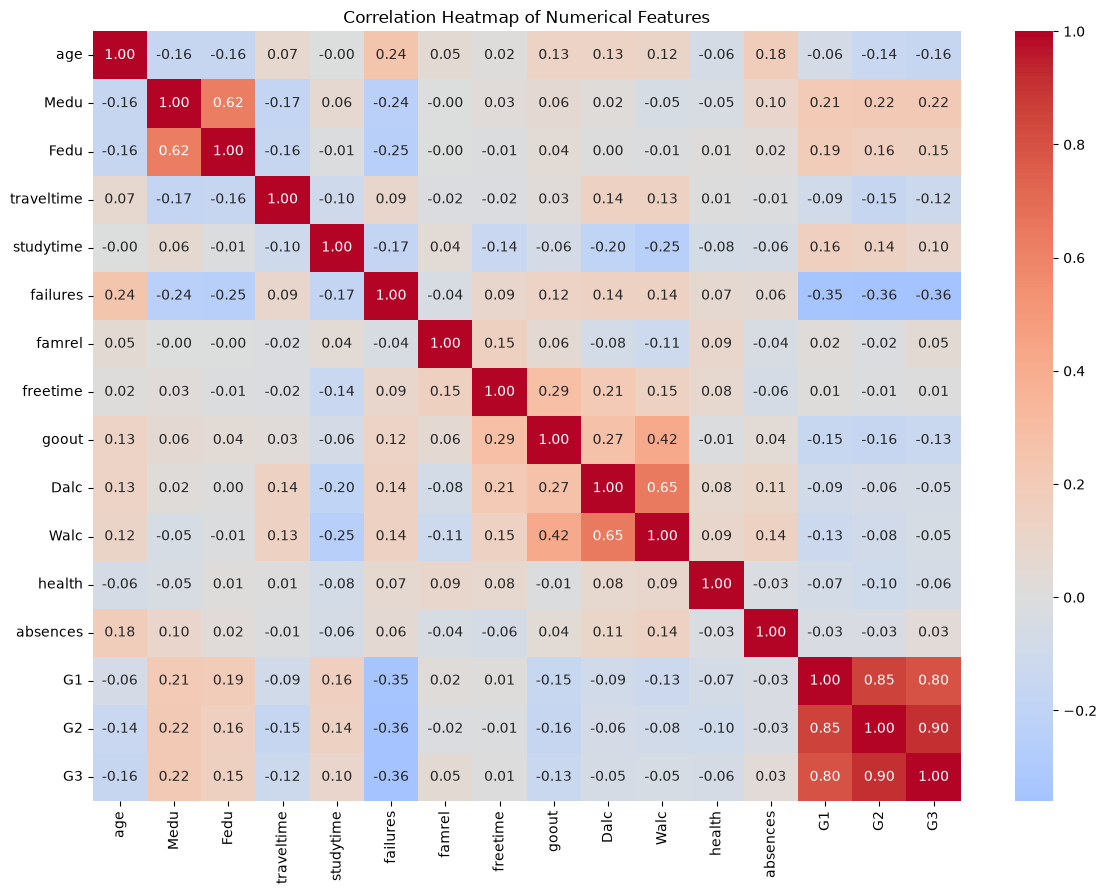

In [73]:
correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

**Interpretation:**

The correlation heatmap shows the strength and direction of relationships between numerical variables.

Values closer to +1 indicate a stronger positive relationship, while values closer to -1 indicate a stronger negative relationship. Values near 0 indicate a weak linear relationship.

The heatmap helps identify variables that are strongly associated with the final grade (`G3`) and relationships between other academic and demographic variables.

In [74]:
g3_correlation = correlation_matrix["G3"].sort_values(ascending=False)

print("Correlation of numerical features with Final Grade (G3):")
print(g3_correlation)

Correlation of numerical features with Final Grade (G3):
G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


**Interpretation:**

This ranking identifies the numerical variables with the strongest positive and negative linear relationships with final grade (`G3`). It provides a focused view of which numerical factors are most closely associated with academic performance in this dataset.

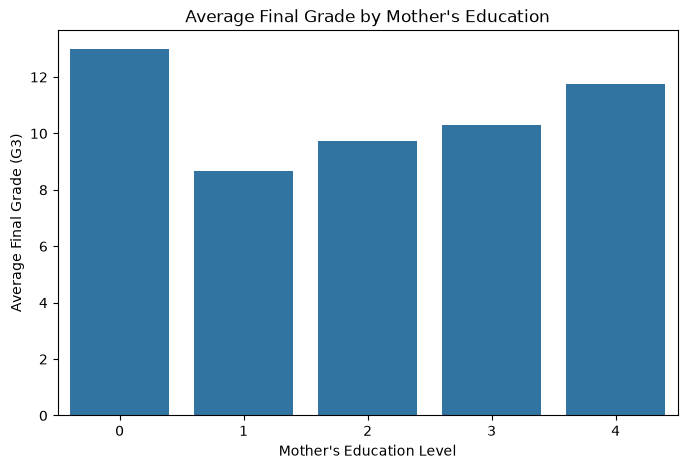

In [75]:
mother_edu_g3 = df.groupby("Medu")["G3"].mean().reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(data=mother_edu_g3, x="Medu", y="G3")

plt.title("Average Final Grade by Mother's Education")
plt.xlabel("Mother's Education Level")
plt.ylabel("Average Final Grade (G3)")
plt.show()

**Interpretation:**

The chart compares average final grades across different levels of mother's education. It provides a descriptive view of whether students from different parental-education groups show differences in average academic performance.

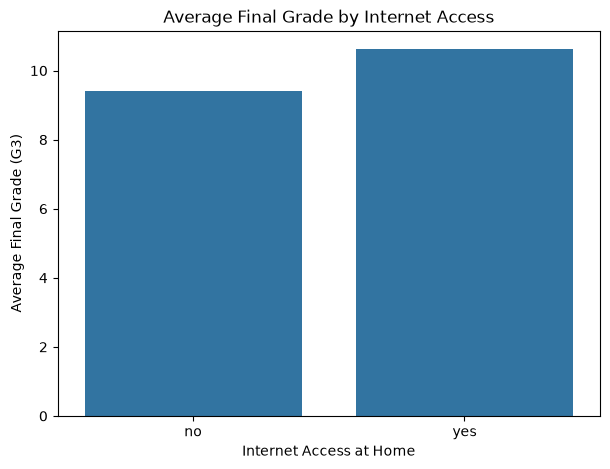

In [76]:
internet_g3 = df.groupby("internet")["G3"].mean().reset_index()

plt.figure(figsize=(7, 5))

sns.barplot(data=internet_g3, x="internet", y="G3")

plt.title("Average Final Grade by Internet Access")
plt.xlabel("Internet Access at Home")
plt.ylabel("Average Final Grade (G3)")
plt.show()

**Interpretation:**

The chart compares average final grades between students with and without internet access at home. It provides a descriptive view of the relationship between access to this resource and academic performance.

## 7. Key Findings & Insights

The exploratory analysis provides the following observations about student academic performance:

1. **Final Grade Distribution:**  
   The distribution of `G3` shows how final academic performance varies across students.

2. **Study Time:**  
   Students are distributed across different weekly study-time categories. The comparison of average `G3` across these categories helps examine the association between study time and final performance.

3. **Previous Failures:**  
   Average final grades vary across groups with different numbers of previous failures, indicating an association between previous academic history and final performance.

4. **Absences:**  
   The absence distribution contains students with different attendance levels. The scatter plot allows us to examine the relationship between absences and final grades.

5. **Gender:**  
   The dataset contains students from both gender categories, and their average final grades can be compared descriptively.

6. **Parental Education:**  
   Average final grades vary across different levels of mother's education, providing insight into the relationship between family educational background and student performance.

7. **Internet Access:**  
   Average final grades can be compared between students with and without internet access at home.

8. **Correlation Analysis:**  
   The correlation matrix identifies numerical variables that have stronger or weaker linear associations with the final grade (`G3`).

9. **Outliers:**  
   Box plots and the IQR-based analysis help identify observations that may be unusually high or low in variables such as absences and grades.

> **Note:** These findings describe associations observed in the dataset. They do not establish that any particular factor directly causes changes in academic performance.

In [77]:
print("Student Performance Summary")
print("-" * 30)
print("Total students:", len(df))
print("Average Final Grade (G3):", round(df["G3"].mean(), 2))
print("Median Final Grade (G3):", df["G3"].median())
print("Highest Final Grade:", df["G3"].max())
print("Lowest Final Grade:", df["G3"].min())
print("Average Absences:", round(df["absences"].mean(), 2))

Student Performance Summary
------------------------------
Total students: 395
Average Final Grade (G3): 10.42
Median Final Grade (G3): 11.0
Highest Final Grade: 20
Lowest Final Grade: 0
Average Absences: 5.71


## 8. Conclusion

This exploratory data analysis examined the Student Performance dataset to understand the demographic, academic, family, and behavioral characteristics of students.

The analysis covered data understanding, data quality checks, univariate analysis, bivariate analysis, multivariate analysis, correlation analysis, and outlier detection.

The visualizations helped identify patterns and associations involving final academic performance (`G3`), study time, previous failures, absences, parental education, gender, and internet access.

Overall, the EDA provides a structured understanding of the factors associated with student academic performance and establishes a foundation for further analysis.

### Next Steps

- Perform deeper statistical analysis of the observed relationships.
- Investigate important predictors of final academic performance.
- Apply suitable machine learning techniques if required.
- Evaluate model performance using appropriate metrics.
- Consider explainability techniques to better understand model predictions.

## 9. BLEEP EDA Requirements Checklist

- [x] Dataset loading and understanding
- [x] Dataset dimensions and structure
- [x] Data types
- [x] Descriptive statistics
- [x] Data dictionary
- [x] Missing-value analysis
- [x] Duplicate analysis
- [x] Data validity checks
- [x] Outlier analysis
- [x] Univariate analysis
- [x] Bivariate analysis
- [x] Multivariate analysis
- [x] 3 Histograms
- [x] 3 Box plots
- [x] 3 Bar charts
- [x] 2 Count plots
- [x] 2 Scatter plots
- [x] Correlation heatmap
- [x] 2 Additional meaningful visualizations
- [x] Interpretation of visualizations
- [x] Key findings and insights
- [x] Conclusion and next steps

**Time-series analysis:** Not applicable because the dataset does not contain a time-based variable.